# The stimulus and cue frames

The **stimulus** and **cue** panels of the task schematic in
[`../../figure_1/task/trial_structure.ipynb`](../../figure_1/task/trial_structure.ipynb),
on their own: one rendered frame of a 2-object trial with both objects on screen, and one of
the moment the cue appears, for use beside this directory's model figures.

Same trial, same renderer and the same sprite bookkeeping as that notebook, so each panel is
the one it draws rather than a lookalike. Only these two phases are rendered — the other four
are not built at all, which is why this runs in a second where the full schematic renders
every timestep of the trial.

The pair is the binding problem in two pictures: the stimulus frame is what the population
sees, and the cue frame is the moment the animal is told *which* object to report — the
ordering information this directory's model carries through a separate low-capacity channel.

**Kernel:** the renderer needs `moog` and `pynwb` → run this with the **Python (wm_paper)**
kernel.

In [1]:
# ── CONFIG ───────────────────────────────────────────────────────────────────
SUBJECT      = 'Perle'
SESSION      = '2022-06-11'
TRIAL_NUMBER = 200          # a 2-object trial — the one the task schematic uses

# Which frame within each phase: its middle, plus this offset
FRAME_OFFSET = {'stimulus': 0, 'cue': 0}

FIGSIZE    = (1.5, 1.5)     # figure size in inches (one square panel)
TITLES     = {'stimulus': None, 'cue': None}   # e.g. 'Cue (180ms)' to label a panel
OUTPUT_PDF = {'stimulus': 'stimulus_frame.pdf', 'cue': 'cue_frame.pdf'}
# ─────────────────────────────────────────────────────────────────────────────

In [2]:
import ast
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pynwb import NWBHDF5IO

sys.path.append('..')
import common

common.set_style()

_ROOT = Path('../../..')                            # paper root, from this directory
sys.path.append(str(_ROOT / 'data_exploration/task_visualization'))  # renderer + task-state helpers (needs `moog`)
import task_state as task_state_lib
import renderer as renderer_lib

## Load the trial

In [3]:
nwb_file_path = (_ROOT / f'cache/dandi_data/behavior/sub-{SUBJECT}/'
                         f'sub-{SUBJECT}_ses-{SESSION}_behavior+task.nwb')
with NWBHDF5IO(nwb_file_path, 'r') as io:
    nwbfile = io.read()
    all_trials_df = nwbfile.trials.to_dataframe()
    all_display_df = nwbfile.intervals['display'].to_dataframe()

trial_df = all_trials_df.loc[TRIAL_NUMBER]
display_df = all_display_df[
    (all_display_df['start_time'] > trial_df['start_time']) &
    (all_display_df['stop_time'] < trial_df['stop_time'])
].reset_index(drop=True)

n_objects = len(ast.literal_eval(trial_df.stimulus_object_positions))
print(f'{SUBJECT} {SESSION} trial {TRIAL_NUMBER}: {n_objects} objects, '
      f'{display_df.shape[0]} timesteps, broke_fixation={trial_df["broke_fixation"]}')
assert not trial_df['broke_fixation'], 'Expected a completed trial'

Perle 2022-06-01 trial 41: 2 objects, 202 timesteps, broke_fixation=False


## Rendering one phase at a time

The sprite settings below are `trial_structure.ipynb`'s, per phase. **Stimulus:** both
objects fully opaque, the fixation cross at that timestep's scale. **Cue:** objects hidden,
fixation cross hidden, the cue sprite revealed, and the background blanked exactly as the
delay left it (`delay_object_blanks`). In both, the eye sprite is hidden — that marker
belongs to the response and feedback panels — and the foveal window keeps the hidden default
`get_task_state` gives it.

In [4]:
phase_arr = display_df['task_phase'].to_numpy()
stim_positions = ast.literal_eval(trial_df.stimulus_object_positions)
stim_identities = ast.literal_eval(trial_df.stimulus_object_identities)
stim_target = [x == 'true' for x in trial_df.stimulus_object_target[1:-1].split(', ')]
renderer = renderer_lib.Renderer()


def render_frame(phase, offset=0):
    """One rendered frame of `phase`: its middle timestep, plus `offset`.

    The task state is rebuilt from scratch for each phase rather than carried forward, as
    `trial_structure.ipynb` does when it walks the whole trial — the sprite settings below
    are that notebook's for this phase, written out in full so a phase can be drawn without
    the ones before it.
    """
    where = np.where(phase_arr == phase)[0]
    assert len(where), f'this trial has no {phase} phase'
    timestep = int(where[int(np.clip(len(where) // 2 + offset, 0, len(where) - 1))])

    task_state = task_state_lib.get_task_state(stim_positions, stim_identities, stim_target)
    eye = display_df.loc[timestep, 'closed_loop_eye_position']
    task_state['fixation'][0].scale = display_df.loc[timestep, 'fixation_cross_scale']
    task_state['eye'][0].opacity = 0        # the eye marker is a response/feedback thing
    task_state['eye'][0].position = eye
    task_state['fw'][0].position = eye

    blank = False
    if phase == 'stimulus':
        for p in task_state['prey']:
            p.opacity = 255                 # both objects on screen
    elif phase == 'cue':
        task_state['fixation'][0].opacity = 0   # the fixation cross gives way to the cue
        for p in task_state['prey']:
            p.opacity = 0                   # the objects are long gone by the cue
        task_state['cue'][0].opacity = 255
        blank = trial_df.delay_object_blanks
    else:
        raise ValueError(f'{phase!r} is not one of the phases this notebook draws')
    frame = renderer(task_state, trial_df.background_indices, blank=blank)
    print(f'{phase}: timestep {timestep} of {where[0]}-{where[-1]}, '
          f'frame {frame.shape[1]} x {frame.shape[0]} px')
    return frame


def show_frame(frame, phase):
    """Draw one frame as its own square panel and save it."""
    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.imshow(frame)
    if TITLES.get(phase):
        ax.set_title(TITLES[phase])
    ax.set_xticks([])
    ax.set_yticks([])
    fig.tight_layout()
    common.save(fig, OUTPUT_PDF[phase])
    plt.show()

## The stimulus frame

What the population sees: both objects on the noise background, fixation cross at center.

stimulus: timestep 62 of 32-91, frame 512 x 512 px
saved stimulus_frame.pdf


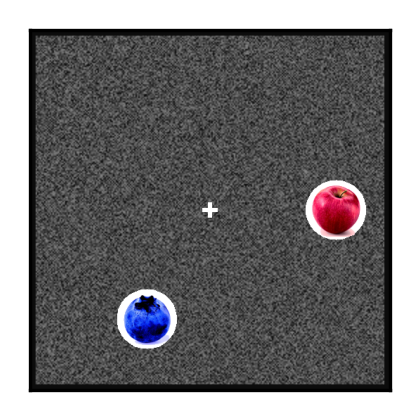

In [5]:
show_frame(render_frame('stimulus', FRAME_OFFSET['stimulus']), 'stimulus')

## The cue frame

The moment the animal is told which object to report: the objects are gone, the fixation
cross is replaced by the cue sprite, and the background carries the delay's blanking.

cue: timestep 159 of 152-166, frame 512 x 512 px
saved cue_frame.pdf


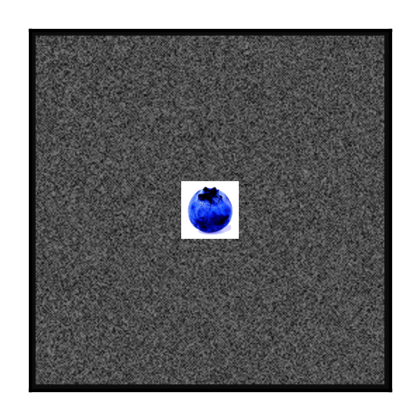

In [6]:
show_frame(render_frame('cue', FRAME_OFFSET['cue']), 'cue')